<a href="https://colab.research.google.com/github/Philip5717021/Philip5717021-DataScience-GenAI-Submissions/blob/main/Copy_of_5_01_Random_Forest_and_GBDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 5.01 Random Forest and Gradient Boosting Decision Trees
In this notebook we will extend the solution to last week's notebook by also looking at Random Forest and two GBDT implementations (the native scikit-learn implementation and also _eXtreme Gradient Boosting Decision Trees_ - _XGBDT_). The latter is basically a slighly more sophisticated implementation.

We start with a prepared dataset available on my.wbs:




In [ ]:
from google.colab import files
uploaded = files.upload()

Saving credit_data_final.csv to credit_data_final.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('credit_data_final.csv')

y_value = df['class'] # set the y
y_values = np.ravel(y_value) # change to an array (list)

x_values = df.drop('class', axis=1) # drop the y from the dataframe

# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.2, random_state=4567, stratify=y_value)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(800, 28)
(200, 28)
(800,)
(200,)


## Modeling and Evaluation
We will set up algorithms for logistic regression (the previous winner) and then our new algorithms.

Just to look at the impact of hyperparameter optimisation, we will set them up initially with default hyperparameters and compare their performance (on the training data):

In [ ]:
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB
from sklearn.metrics import precision_recall_fscore_support

LogR_algo = LogR()
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF()
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT()
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB()
XGB_model = XGB_algo.fit(X_train, Y_train)

models = [LogR_model, RF_model, GBDT_model, XGB_model]
names = ['Logistic Regression', 'Random Forest', 'GBDT', 'XGBDT']

for i in range(4):
  print(f"Model: {names[i]}")

  # predict based on training data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")


Model: Logistic Regression
Macro Precision: 0.695493494128848
Macro Recall: 0.6145833333333334
Macro F1-score: 0.6216980598450139


Model: Random Forest
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


Model: GBDT
Macro Precision: 0.8959161405969917
Macro Recall: 0.8401785714285714
Macro F1-score: 0.8614536616244558


Model: XGBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




Random Forest and XGBDT score perfectly - but is it overfitting? Let's hyperparameter tune them and see the scores again (on training data):

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# we get a load of warnings running the code so will supress them
import warnings
warnings.filterwarnings("ignore")

# create a hyperparameter search function for re-usability
def random_search(algo, hyperparameters, X_train, Y_train):
  # do the search using 5 folds/chunks
  clf = RandomizedSearchCV(algo, hyperparameters, cv=5, random_state=2015,
                          scoring='precision_macro', n_iter=20, refit=True)

  # pass the data to fit/train
  clf.fit(X_train, Y_train)

  return clf.best_params_

# Logistic Regression
LogR_tuned_parameters = {
    'solver': ['liblinear'], # only this one as it does both L1 and L2
    # C is the equivalent of alpha in L1/L2 regression - how much regularisation
    'C': uniform(loc=0.1, scale=19.9),  # Draw from a uniform distribution between 0.1 and 20
    'penalty': ['l1', 'l2', 'elasticnet', None] # elasticnet is a mix of L1 and L2
}

LogR_best_params = random_search(LogR_algo, LogR_tuned_parameters, X_train, Y_train)


# Random Forest
RF_tuned_parameters = {
    'n_estimators': randint(50, 500), # Draw from a uniform distribution between 50 and 500
    'max_depth': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'min_samples_split': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'max_features': ['sqrt', 'log2', None]
}

RF_best_params = random_search(RF_algo, RF_tuned_parameters, X_train, Y_train)


# GBDT
GBDT_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    'learning_rate': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

GBDT_best_params = random_search(GBDT_algo, GBDT_tuned_parameters, X_train, Y_train)


# XGBDT
XGB_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    # eta is learning rate
    'eta': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    # objective is the same as criterion
    'objective': ['binary:logistic', 'binary:hinge'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

XGB_best_params = random_search(XGB_algo, XGB_tuned_parameters, X_train, Y_train)


# Train the models
LogR_algo = LogR(**LogR_best_params)
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF(**RF_best_params)
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT(**GBDT_best_params)
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB(**XGB_best_params)
XGB_model = XGB_algo.fit(X_train, Y_train)


# score the models
models = [LogR_model, RF_model, GBDT_model, XGB_model] # redo this or it uses the old models

for i in range(len(models)): # for every model in the models list
  print(f"Model: {names[i]}")

  # predict based on training data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6981523631008166
Macro Recall: 0.6211309523809524
Macro F1-score: 0.629761289933129


Model: Random Forest
Macro Precision: 0.856234096692112
Macro Recall: 0.5291666666666667
Macro F1-score: 0.4711656585274538


Model: GBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


Model: XGBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




Our scores are ... a bit different from last time. In fact GBDT went up to perfect. However, the real test is the score on our test data:

In [ ]:
for i in range(4):
  print(f"Model: {names[i]}")

  # predict based on TEST data
  predict = models[i].predict(X_test)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6376488095238095
Macro Recall: 0.5880952380952381
Macro F1-score: 0.590626764539808


Model: Random Forest
Macro Precision: 0.8571428571428572
Macro Recall: 0.5333333333333333
Macro F1-score: 0.4791666666666667


Model: GBDT
Macro Precision: 0.775521579869406
Macro Recall: 0.705952380952381
Macro F1-score: 0.7248229806369342


Model: XGBDT
Macro Precision: 0.6741164241164241
Macro Recall: 0.6595238095238095
Macro F1-score: 0.6651785714285714




Similar to last time, our best scorer for our prefered metric (_macro precision_) scores worse for everything else. We can make a good case to look further at both Random Forest and GBDT. So let's do that:

Random Forest Confusion Matrix


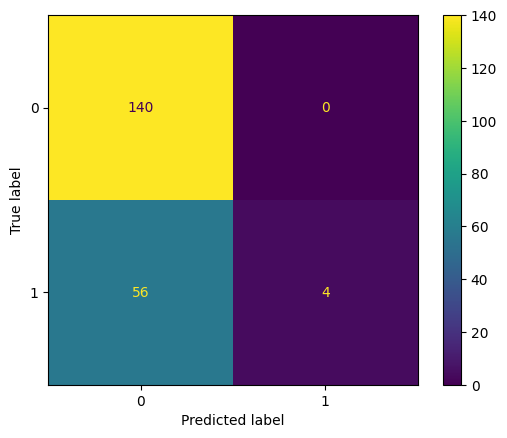

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# Random Forest
print("Random Forest Confusion Matrix")
predict = RF_model.predict(X_test)
CM.from_predictions(Y_test, predict)

GBDT Confusion Matrix


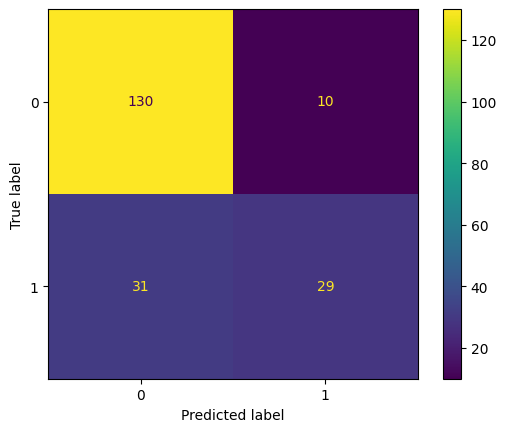

In [ ]:
# GBDT
print("GBDT Confusion Matrix")
predict = GBDT_model.predict(X_test)
print(CM.from_predictions(Y_test, predict))

We can see they are wrong in different ways. Because we care most about minimising cases we predict "0" (good to loan to) and in fact they are a "1" (bad to loan to), GBDT should be best. Random Forest misclassifies 56 cases in this way (more than Logistic Regression), while GBDT only 31. Also, random forest only predicts "1" a total of 4 times. GBDT is much more balanced in the predictions it makes for each class.

So GBDT is the winner.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving credit_data_final.csv to credit_data_final (1).csv


In [ ]:
# 1. View the first 5 rows of the dataset
print("--- First 5 Rows of Credit Dataset ---")
display(df.head())

# 2. Check dataset shape (rows, columns)
print(f"\nDataset dimensions: {df.shape[0]} rows and {df.shape[1]} columns.")

# 3. List all column names
print("\n--- List of Columns ---")
print(list(df.columns))

# 4. Check for missing values in each column
print("\n--- Missing Values Count per Column ---")
missing_vals = df.isnull().sum()
# Only display columns with missing values to keep it simple, or confirm if there are none
if missing_vals.sum() == 0:
    print("Great news! There are no missing values in the dataset.")
else:
    display(missing_vals[missing_vals > 0])

--- First 5 Rows of Credit Dataset ---


,checking_status,duration,credit_amount,savings_status,employment,installment_commitment,residence_since,age,housing,existing_credits,...,type__none,type__life insurance,type__no known property,type__real estate,type__skilled,type__unemp/unskilled non res,type__unskilled resident,type__none.1,type__stores,gender
0,0.333333,0.029412,0.050567,0.00,1.00,1.000000,1.000000,0.857143,1.0,0.333333,...,1,0,0,1,1,0,0,1,0,0
1,0.666667,0.647059,0.313690,0.25,0.50,0.333333,0.333333,0.053571,1.0,0.000000,...,1,0,0,1,1,0,0,1,0,1
2,0.000000,0.117647,0.101574,0.25,0.75,0.333333,0.666667,0.535714,1.0,0.000000,...,1,0,0,1,0,0,1,1,0,0
3,0.333333,0.558824,0.419941,0.25,0.75,0.333333,1.000000,0.464286,0.0,0.000000,...,0,1,0,0,1,0,0,1,0,0
4,0.333333,0.294118,0.254209,0.25,0.50,0.666667,1.000000,0.607143,0.0,0.333333,...,1,0,1,0,1,0,0,1,0,0



Dataset dimensions: 1000 rows and 29 columns.

--- List of Columns ---
['checking_status', 'duration', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'residence_since', 'age', 'housing', 'existing_credits', 'num_dependents', 'own_telephone', 'foreign_worker', 'class', 'type__critical/other existing credit', 'type__delayed previously', 'type__existing paid', 'type__no credits/all paid', 'type__guarantor', 'type__none', 'type__life insurance', 'type__no known property', 'type__real estate', 'type__skilled', 'type__unemp/unskilled non res', 'type__unskilled resident', 'type__none.1', 'type__stores', 'gender']

--- Missing Values Count per Column ---
Great news! There are no missing values in the dataset.


In [ ]:
# 1. Separate target variable (y) and feature variables (X)
target_column = 'class'
y = df[target_column]
X = df.drop(columns=[target_column])

# 2. Check if encoding or cleaning is needed
print("--- Data Preparation Audit ---")
print(f"Target Variable: '{target_column}'")
print(f"Number of Features: {X.shape[1]}")

# Quick check on data types to ensure all features are numeric
non_numeric_cols = X.select_dtypes(exclude=['number']).columns.tolist()
if len(non_numeric_cols) == 0:
    print("\n- All features are already numeric/encoded. No further encoding is needed!")
else:
    print(f"\n- Non-numeric columns found that may need encoding: {non_numeric_cols}")

# 3. Split the dataset into training (80%) and test (20%) sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\n--- Split Summary ---")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

--- Data Preparation Audit ---
Target Variable: 'class'
Number of Features: 28

- All features are already numeric/encoded. No further encoding is needed!

--- Split Summary ---
Training set shape: (800, 28)
Testing set shape: (200, 28)


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset: 80% training, 20% testing
# We use 'stratify=y' to maintain class balance and 'random_state=42' for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Print the shapes to confirm the split
print("--- Dataset Split Complete ---")
print(f"X_train (Training features): {X_train.shape}")
print(f"X_test (Testing features):   {X_test.shape}")
print(f"y_train (Training targets):  {y_train.shape}")
print(f"y_test (Testing targets):    {y_test.shape}")

--- Dataset Split Complete ---
X_train (Training features): (800, 28)
X_test (Testing features):   (200, 28)
y_train (Training targets):  (800,)
y_test (Testing targets):    (200,)


In [ ]:
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB

# Initialize the models
# Since your data is already preprocessed (fully numeric & scaled), we can train them directly.
log_reg = LogR(random_state=42)
random_forest = RF(random_state=42)
gbdt = GBDT(random_state=42)
xgb = XGB(random_state=42, use_label_encoder=False, eval_metric='logloss')

# Train each model on the training set
print("Training models...")
log_reg.fit(X_train, y_train)
print("- Logistic Regression: Trained successfully")

random_forest.fit(X_train, y_train)
print("- Random Forest: Trained successfully")

gbdt.fit(X_train, y_train)
print("- Gradient Boosting (GBDT): Trained successfully")

xgb.fit(X_train, y_train)
print("- XGBoost: Trained successfully")

Training models...
- Logistic Regression: Trained successfully
- Random Forest: Trained successfully
- Gradient Boosting (GBDT): Trained successfully


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:38:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


- XGBoost: Trained successfully


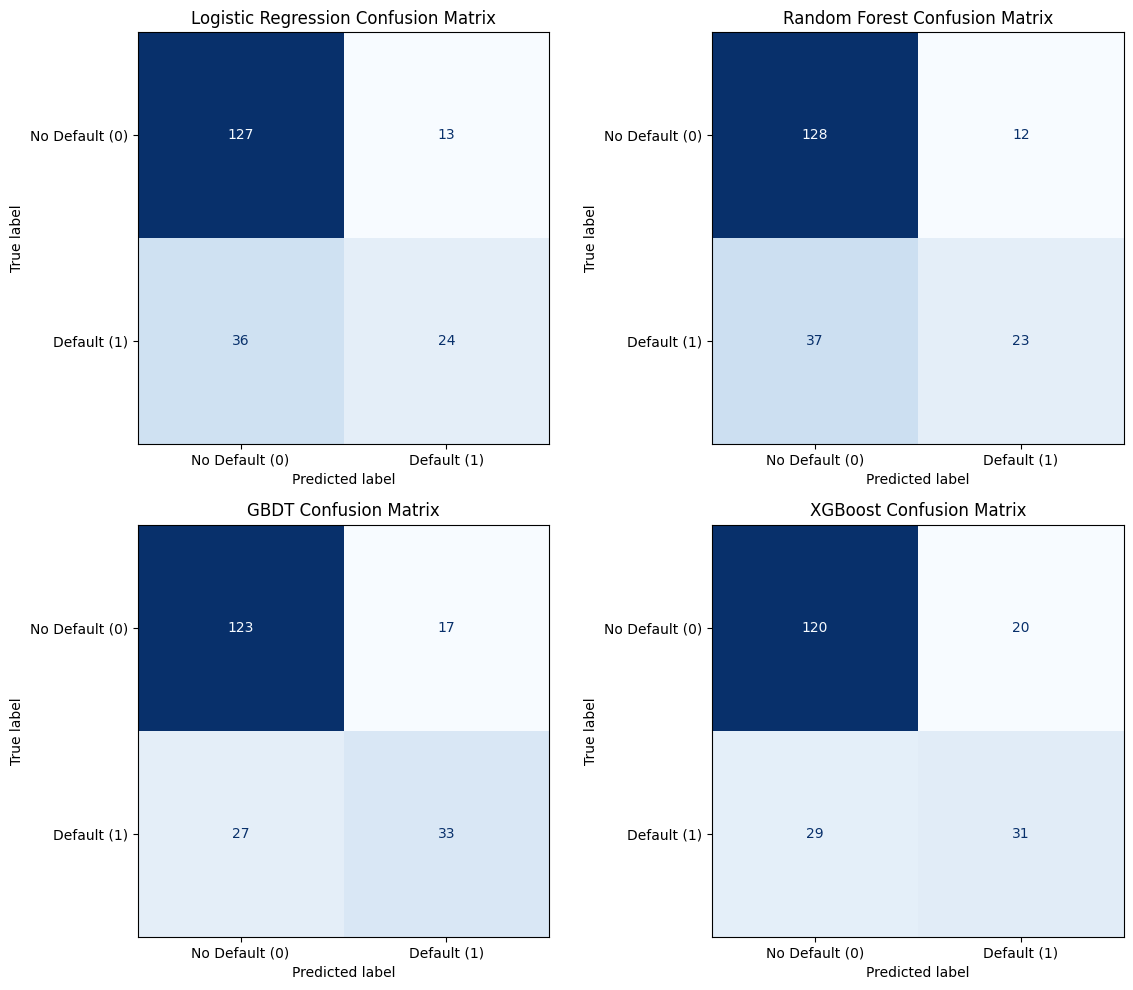


--- Model Performance Comparison on Test Set ---


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
0,Logistic Regression,\n75.50%,64.86%,40.00%,49.48%
1,Random Forest,\n75.50%,65.71%,38.33%,48.42%
2,GBDT,\n78.00%,66.00%,55.00%,60.00%
3,XGBoost,\n75.50%,60.78%,51.67%,55.86%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Group models and names
models = [log_reg, random_forest, gbdt, xgb]
names = ['Logistic Regression', 'Random Forest', 'GBDT', 'XGBoost']

results = []

# Configure subplot layout for confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (model, name) in enumerate(zip(models, names)):
    # Predict on the test set
    y_pred = model.predict(X_test)

    # Calculate metrics (focusing on class 1 - default)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Store results
    results.append({
        'Model': name,
        'Accuracy': f"\n{accuracy:.2%}",
        'Precision (Class 1)': f"{precision:.2%}",
        'Recall (Class 1)': f"{recall:.2%}",
        'F1-Score (Class 1)': f"{f1:.2%}"
    })

    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default (0)', 'Default (1)'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

# Display Comparison Table
df_results = pd.DataFrame(results)
print("\n--- Model Performance Comparison on Test Set ---")
display(df_results)

In [ ]:
import numpy as np
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB

# Calculate class scale factor for XGBoost class weighting
# sum(negative instances) / sum(positive instances)
ratio = (len(y_train) - sum(y_train)) / sum(y_train)

# 1. Parameter Distributions
log_reg_dist = {
    'C': uniform(loc=0.01, scale=10.0),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'],
    'class_weight': ['balanced', None]
}

rf_dist = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(3, 10),
    'min_samples_split': randint(2, 10),
    'class_weight': ['balanced', 'balanced_subsample', None]
}

gbdt_dist = {
    'n_estimators': randint(50, 200),
    'learning_rate': uniform(loc=0.01, scale=0.3),
    'max_depth': randint(3, 8)
}

xgb_dist = {
    'n_estimators': randint(50, 200),
    'learning_rate': uniform(loc=0.01, scale=0.3),
    'max_depth': randint(3, 8),
    'scale_pos_weight': [1, ratio, ratio * 1.5] # focus heavily on defaults
}

# Initialize base estimators
base_lr = LogR(random_state=42)
base_rf = RF(random_state=42)
base_gb = GBDT(random_state=42)
base_xgb = XGB(random_state=42, use_label_encoder=False, eval_metric='logloss')

# 2. Setup Randomized Search targeting F1-score
print("Optimizing models for Class 1 (Default) using F1-score as metric...")

lr_search = RandomizedSearchCV(base_lr, log_reg_dist, n_iter=15, cv=5, scoring='f1', random_state=42, n_jobs=-1)
rf_search = RandomizedSearchCV(base_rf, rf_dist, n_iter=15, cv=5, scoring='f1', random_state=42, n_jobs=-1)
gb_search = RandomizedSearchCV(base_gb, gbdt_dist, n_iter=15, cv=5, scoring='f1', random_state=42, n_jobs=-1)
xgb_search = RandomizedSearchCV(base_xgb, xgb_dist, n_iter=15, cv=5, scoring='f1', random_state=42, n_jobs=-1)

# Fit on Training Data Only
print("Fitting Logistic Regression...")
lr_search.fit(X_train, y_train)
tuned_log_reg = lr_search.best_estimator_

print("Fitting Random Forest...")
rf_search.fit(X_train, y_train)
tuned_random_forest = rf_search.best_estimator_

print("Fitting GBDT...")
gb_search.fit(X_train, y_train)
tuned_gbdt = gb_search.best_estimator_

print("Fitting XGBoost...")
xgb_search.fit(X_train, y_train)
tuned_xgb = xgb_search.best_estimator_

print("\n--- Optimization Complete! ---")
print("Best LR params:", lr_search.best_params_)
print("Best RF params:", rf_search.best_params_)
print("Best GBDT params:", gb_search.best_params_)
print("Best XGBoost params:", xgb_search.best_params_)

Optimizing models for Class 1 (Default) using F1-score as metric...
Fitting Logistic Regression...
Fitting Random Forest...
Fitting GBDT...
Fitting XGBoost...

--- Optimization Complete! ---
Best LR params: {'C': np.float64(1.5701864044243652), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Best RF params: {'class_weight': 'balanced_subsample', 'max_depth': 5, 'min_samples_split': 8, 'n_estimators': 124}
Best GBDT params: {'learning_rate': np.float64(0.2996896099223678), 'max_depth': 4, 'n_estimators': 58}
Best XGBoost params: {'learning_rate': np.float64(0.03718193035984624), 'max_depth': 5, 'n_estimators': 157, 'scale_pos_weight': 3.5}


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:45:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create lists of original and tuned models with their labels
original_models = [log_reg, random_forest, gbdt, xgb]
tuned_models = [tuned_log_reg, tuned_random_forest, tuned_gbdt, tuned_xgb]
names = ['Logistic Regression', 'Random Forest', 'GBDT', 'XGBoost']

comparison_rows = []

for name, orig_model, tuned_model in zip(names, original_models, tuned_models):
    # 1. Evaluate Original Model
    orig_preds = orig_model.predict(X_test)
    orig_acc = accuracy_score(y_test, orig_preds)
    orig_prec = precision_score(y_test, orig_preds)
    orig_rec = recall_score(y_test, orig_preds)
    orig_f1 = f1_score(y_test, orig_preds)

    # 2. Evaluate Tuned Model
    tuned_preds = tuned_model.predict(X_test)
    tuned_acc = accuracy_score(y_test, tuned_preds)
    tuned_prec = precision_score(y_test, tuned_preds)
    tuned_rec = recall_score(y_test, tuned_preds)
    tuned_f1 = f1_score(y_test, tuned_preds)

    # Add original results to rows
    comparison_rows.append({
        'Model': f"{name} (Original)",
        'Accuracy': f"{orig_acc:.2%}",
        'Precision (Class 1)': f"{orig_prec:.2%}",
        'Recall (Class 1)': f"{orig_rec:.2%}",
        'F1-Score (Class 1)': f"{orig_f1:.2%}"
    })

    # Add tuned results to rows
    comparison_rows.append({
        'Model': f"{name} (Tuned)",
        'Accuracy': f"{tuned_acc:.2%}",
        'Precision (Class 1)': f"{tuned_prec:.2%}",
        'Recall (Class 1)': f"{tuned_rec:.2%}",
        'F1-Score (Class 1)': f"{tuned_f1:.2%}"
    })

# Construct and display DataFrame
comparison_df = pd.DataFrame(comparison_rows)
print("--- Model Evaluation Comparison (Original vs. Tuned) ---")
display(comparison_df)

--- Model Evaluation Comparison (Original vs. Tuned) ---


,Model,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
0,Logistic Regression (Original),75.50%,64.86%,40.00%,49.48%
1,Logistic Regression (Tuned),64.50%,44.33%,71.67%,54.78%
2,Random Forest (Original),75.50%,65.71%,38.33%,48.42%
3,Random Forest (Tuned),71.00%,51.19%,71.67%,59.72%
4,GBDT (Original),78.00%,66.00%,55.00%,60.00%
5,GBDT (Tuned),77.50%,65.31%,53.33%,58.72%
6,XGBoost (Original),75.50%,60.78%,51.67%,55.86%
7,XGBoost (Tuned),67.00%,46.67%,70.00%,56.00%


The results demonstrate that hyperparameter tuning improved recall for Logistic Regression, Random Forest and XGBoost, although this generally came at the expense of overall accuracy. The original GBDT achieved the highest accuracy (78%) and F1-score (60%), suggesting the strongest overall performance among the models tested. However, the tuned Random Forest and Logistic Regression achieved the highest recall (71.67%), identifying a greater proportion of customers who actually defaulted. Therefore, the most appropriate model depends on whether the bank prioritises overall predictive performance or identifying potential loan defaults.